# Notebook 01: Data preparation

**Goal:** turn the raw Flipkart review file into a clean, labelled electronics dataset that a model can learn from.

**Input:** `data/raw/Dataset-SA 2.csv` (download from Kaggle, see the README)
**Output:** `data/processed/reviews_electronics_clean.csv`

**What we do, in order**
1. Load the data and look at it
2. Check quality: missing values and duplicates
3. Create our own sentiment labels from star ratings
4. Look at repeated review texts (label noise)
5. Keep only electronics products
6. Clean the review text
7. Save the result

*Why a notebook?* A notebook runs code in small cells with the explanation next to it, so anyone can follow the reasoning. Run the cells from top to bottom with Shift+Enter.

## Step 0: Setup

In [1]:
import os, sys

# Make sure we run from the project root, so paths like "data/raw/..." work
# whether this notebook is opened from the root or from the notebooks/ folder.
root = os.getcwd() if os.path.isdir("src") else os.path.abspath("..")
os.chdir(root)
sys.path.insert(0, root)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocess import clean_text
from src.electronics_filter import is_electronics

pd.set_option("display.max_colwidth", 80)
RAW_PATH = "data/raw/Dataset-SA 2.csv"   # change this if your file has another name

## Step 1: Load the data

`pandas` is the Python library for tables. `read_csv` loads a CSV file into a *DataFrame* (a table, here called `df`).
`shape` shows (number of rows, number of columns).

In [3]:
df = pd.read_csv("data/raw/reviews.csv")
print("shape:", df.shape)
print(df.columns.tolist())
df.head()

shape: (205052, 6)
['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']


,product_name,product_price,Rate,Review,Summary,Sentiment
0,"Candes 12 L Room/Personal Air Cooler??????(White, Black, Elegant High Speed-...",3999,5,super!,great cooler excellent air flow and for this price its so amazing and unbeli...,positive
1,"Candes 12 L Room/Personal Air Cooler??????(White, Black, Elegant High Speed-...",3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,"Candes 12 L Room/Personal Air Cooler??????(White, Black, Elegant High Speed-...",3999,3,fair,the quality is good but the power of air is decent,positive
3,"Candes 12 L Room/Personal Air Cooler??????(White, Black, Elegant High Speed-...",3999,1,useless product,very bad product its a only a fan,negative
4,"Candes 12 L Room/Personal Air Cooler??????(White, Black, Elegant High Speed-...",3999,3,fair,ok ok product,neutral


**What the columns mean**

| Column | Meaning |
|---|---|
| `product_name` | Name of the product on Flipkart |
| `product_price` | Price |
| `Rate` | Star rating (1 to 5) given by the customer |
| `Review` | The review **title** (for example "super!", "fair"). We do **not** use it as a feature, because titles like "useless product" basically state the sentiment already (this is *label leakage*). |
| `Summary` | The actual review **text**. This is our model input. |
| `Sentiment` | A label made by the dataset's author using a tool called VADER. We do **not** train on it (see Step 3). |

## Step 2: Quality checks

Two problems can silently make results look better than they are:
- **Missing text**: rows with no review text cannot be used.
- **Duplicate rows**: if an identical row lands in both the training set and the test set, the model has already "seen the answer". This is called *data leakage*.

In [4]:
print(df.isnull().sum())
print("duplicate rows:", df.duplicated().sum())

product_name         0
product_price        0
Rate                 0
Review           24664
Summary             11
Sentiment            0
dtype: int64
duplicate rows: 34375


In [5]:
before = len(df)
df = df.dropna(subset=["Summary", "Rate"])      # need both text and rating
df = df.drop_duplicates()                       # keep one copy of identical rows
print("rows before:", before, "-> after:", len(df))

rows before: 205052 -> after: 170667


*Expected:* about 205,000 rows before and about 170,600 after. (`Review` is missing in many rows, but we don't use it, so we don't care.)

## Step 3: Create our own sentiment labels from star ratings

We need a "correct answer" (label) for every review so the model can learn. We use the **star rating**, a standard approach for product reviews:

| Stars | Label |
|---|---|
| 4 or 5 | positive |
| 3 | neutral |
| 1 or 2 | negative |

**Why not use the dataset's `Sentiment` column?** It was produced by VADER (a tool that reads the text). If we trained on it, our model would mostly learn to imitate VADER. Customer stars are a more independent signal. The table below compares the two.

In [6]:
df["Rate"] = pd.to_numeric(df["Rate"], errors="coerce")   # bad values become NaN
df = df.dropna(subset=["Rate"])

def rating_to_sentiment(stars):
    if stars >= 4:
        return "positive"
    elif stars == 3:
        return "neutral"
    return "negative"

df["label"] = df["Rate"].apply(rating_to_sentiment)
print(df["label"].value_counts())

# Rows = VADER's label, columns = our star-based label
pd.crosstab(df["Sentiment"], df["label"])

label
positive    130203
negative     26072
neutral      14389
Name: count, dtype: int64


label,negative,neutral,positive
Sentiment,,,
negative,21878,2923,1671
neutral,2231,3320,3948
positive,1963,8146,124584


**What to notice:** VADER and the stars agree for most positive and negative reviews, but disagree a lot on **3-star reviews**. Many 3-star reviews are written politely ("good but battery is average"), so a tool that counts positive words calls them positive.

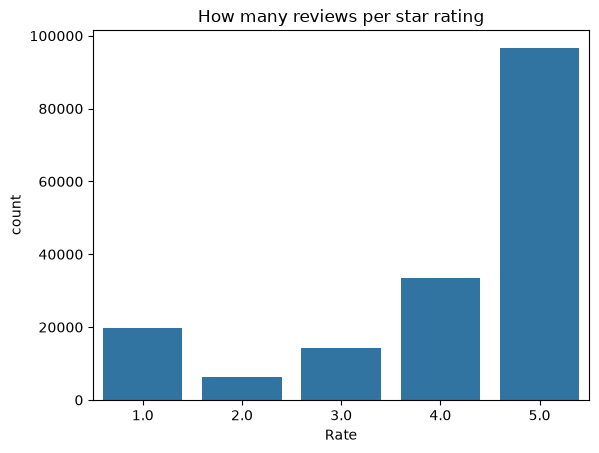

In [7]:
sns.countplot(x="Rate", data=df)
plt.title("How many reviews per star rating")
plt.show()

## Step 4: Repeated texts and label noise

Many customers write the same short text, like "good" or "nice". Let's see how their star ratings differ.

In [8]:
top_texts = df["Summary"].value_counts().head(10).index
subset = df[df["Summary"].isin(top_texts)]
pd.crosstab(subset["Summary"], subset["Rate"])

Rate,1.0,2.0,3.0,4.0,5.0
Summary,,,,,
good,52,23,976,2218,3819
good product,23,10,318,1234,2467
good quality,1,1,83,376,781
nice,25,11,527,1378,2840
nice product,15,7,207,943,2045
ok,31,33,399,405,524
super,8,6,103,443,1610
very good,10,6,79,417,1369
very good product,2,3,45,268,1079


**What to notice:** the same text ("good", "ok") is given different star ratings by different people. Identical text with different labels cannot be told apart by any model, so there is an unavoidable error ceiling, especially for the **neutral** class. This is called *label noise* and it explains why neutral will be our hardest class.

## Step 5: Keep only electronics products

The raw file mixes many categories (dinner sets, kajal, curtains, clothes) with electronics, and has no category column. We use keyword rules on the product name, written in `src/electronics_filter.py`.

**How we know it works:** we hand-check random samples of names the filter *kept* and names it *dropped*. Read them below. If you spot mistakes, add or remove keywords in `src/electronics_filter.py` and rerun.

In [9]:
df["is_electronics"] = is_electronics(df["product_name"])
print(df["is_electronics"].value_counts())
print("unique electronics products:", df.loc[df["is_electronics"], "product_name"].nunique())

is_electronics
False    103260
True      67404
Name: count, dtype: int64
unique electronics products: 284


In [10]:
print("KEPT as electronics (should all be electronics):")
display(df.loc[df["is_electronics"], "product_name"].drop_duplicates()
          .sample(30, random_state=2).to_frame())

KEPT as electronics (should all be electronics):


,product_name
3491,"OnePlus Bullets Wireless Z2 Bluetooth Headset??????(Acoustic Red, In the Ear)"
167229,Hillgrove 10in1 Biggers 25W Soldering Iron Kit 25 W SimpleFlat Pointed Tip
176243,Briqre Victory Nutri Blend 20000 RPM Mixer Grinder 500 Juicer Mixer Grinder ...
136911,ROYAL RJ Round Electric USB Mini Humidifier Aroma Oil Diffuser Air Humidifie...
188145,SAMSUNG EVO Plus 64 GB MicroSDXC Class 10 95 MBs Memory CardWith Adapter
83849,APPLE 2020 Macbook Air M1 - (8 GB/256 GB SSD/Mac OS Big Sur) MGN93HN/AÐÒ?Ð...
13248,SAMSUNG DW60M5042FW/TL Free Standing 13 Place Settings Dishwasher
138478,Crust v50 Car Bluetooth Device with FM Transmitter Audio Receiver Car Charge...
816,"Crompton 75 L Desert Air Cooler??????(White, Teal, ACGC-DAC751)"
89354,"SB 30 W 4 A Mobile 30W -VOOC,DART,FLASH with Type-C Cable Charging Adapter T..."


In [11]:
print("DROPPED as not-electronics (should rarely be electronics):")
display(df.loc[~df["is_electronics"], "product_name"].drop_duplicates()
          .sample(30, random_state=2).to_frame())

DROPPED as not-electronics (should rarely be electronics):


,product_name
69419,"Urban Terrain BOLT UT5000S26 Steel MTB-Disc Brakes, Free Installation & OneF..."
49239,Men Checkered Double Breasted Formal Blazer??????(Blue)
194305,Woodbuzz Engineered Wood Study TableFree Standing Finish Color Walnut Knock...
26433,Glun Water Quality Purity Tester 0-990 PPM Digital TDS Meter
36753,"Jaspo Black Duck Fibre (26"" X 6.5"") Fully Assembled Skateboard (Suitable for..."
102619,HP 805 Tri-Color Ink Cartridge
178843,FOZIA Fabric SofaFinish Color Red Preassembled
16340,"Adonai POT1.5LPINK Rice Cooker, Food Steamer, Travel Cooker, Slow Cooker, El..."
69519,LEADER XTREME 26T REAR SUSPENSION FOR MTB RIDER 26 T Mountain CycleÐÓ®ÐÂ Ð...
41569,"Kamni Sports Premium Swimming Combo of Silicone Swim Cap, Goggles, Nose Clip..."


In [12]:
elec = df[df["is_electronics"]].copy()
print(len(elec), "electronics reviews")
print(elec["label"].value_counts(normalize=True).round(3))

67404 electronics reviews
label
positive    0.778
negative    0.147
neutral     0.075
Name: proportion, dtype: float64


**What to notice:** the data is strongly **imbalanced**, about 78% positive, 15% negative and only 7 to 8% neutral. This is why we will use *macro-F1* (not just accuracy) later.

## Step 6: Clean the review text

Models work with numbers, and text has noise: capital letters, punctuation, repeated letters ("goooood"). We normalise the text with `clean_text` from `src/preprocess.py`. Open that file to see the 10 steps, each commented.

**The important design choice:** standard cleaning deletes words like "not". We **keep negations**, because "not good" and "good" mean opposite things.

In [13]:
examples = [
    "Not good, battery doesn't last!!!",
    "SUPERRRR product READ MORE",
    "dont buy this, cant recommend",
    "Very bad. Can't recommend, waste of money",
]
for text in examples:
    print(repr(text), "->", repr(clean_text(text)))

assert "not" in clean_text("not good")   # negation must survive

"Not good, battery doesn't last!!!" -> 'not good battery not last'
'SUPERRRR product READ MORE' -> 'superr product'
'dont buy this, cant recommend' -> 'not buy not recommend'
"Very bad. Can't recommend, waste of money" -> 'very bad not recommend waste money'


In [14]:
elec["clean_text"] = elec["Summary"].astype(str).apply(clean_text)

# A few reviews become empty after cleaning (for example only emojis): drop them
empty = (elec["clean_text"].str.strip() == "").sum()
print("empty after cleaning:", empty)
elec = elec[elec["clean_text"].str.strip() != ""]
print("final rows:", len(elec))

elec[["Summary", "clean_text", "label"]].sample(8, random_state=3)

empty after cleaning: 3
final rows: 67401


,Summary,clean_text,label
87755,very good product,very good product,positive
18963,just go for it,go,positive
196506,dont buy because camera quality very bad,not buy camera quality very bad,negative
124010,awesome one wonderful no words for praise100 from 100 markssound bass cleari...,awesome one wonderful no word praise markssound bass clearity connectivity no,positive
84311,portable machine in the true sense worth every penny,portable machine true sense worth every penny,positive
114316,value of money,value money,positive
108357,very good router,very good router,positive
135917,super,super,positive


## Step 7: Save the cleaned data

We save the result so the next notebook can start from it. The `data/processed/` folder is ignored by Git (data files are large and can be recreated by running this notebook).

In [15]:
os.makedirs("data/processed", exist_ok=True)
elec.to_csv("data/processed/reviews_electronics_clean.csv", index=False)
print("saved", len(elec), "rows")

saved 67401 rows


**Done.** Next: `02_baseline_model.ipynb`, where we split the data, turn text into numbers and train the first model.